# T32. Simulación de inventario: stock inicial y anclajes por estación

**Objetivo.** Dimensionar cada estación de la red elegida en T28 (`lscp_r300_k159`): cuántos patinetes tiene al empezar el día y cuántos anclajes necesita. Se simula el periodo de ajuste con patinetes y anclajes limitados, reserva del anclaje de destino y rebalanceo nocturno.

**Flota.** Los anclajes salen del dimensionado de este notebook. La flota es la que elige T34 con esos anclajes: **400 patinetes**, la menor que atiende el 95 % de los viajes cubiertos (T34 comprueba que sigue siéndolo). El stock de diseño del P90 (474 patinetes) solo sirve para repartir esa flota entre estaciones.

**Valor.** Da el catálogo de estaciones con coordenadas, stock inicial, anclajes y utilización que piden el enunciado y las fases de consumo y estación de recarga. El simulador (`inventario.py`) es el mismo que usarán T33 (rebalanceo) y T34 (curva de flota).

**Reglas** (PLAN.md, apartado 4):
- Los eventos van en orden temporal. Si una llegada y una salida coinciden en el mismo segundo, primero va la llegada.
- Al aceptar un viaje tiene que haber patinete en el origen, y se reserva un anclaje en el destino hasta que llega. En un viaje circular cuenta el hueco que deja su propia salida.
- Se prueba primero la estación más cercana de cada extremo. Si falta patinete o hueco, se desvía a la siguiente dentro de los 300 m.
- Cada noche, a las 4 h, se recolocan como mucho 100 patinetes (escenario base de `config.yaml`) hacia el stock inicial de cada estación. 0 y 220 son la sensibilidad.
- Los viajes sin estación a menos de 300 m en algún extremo (el 20 % del ajuste, T28) no entran en el inventario.

## 1. Comprobaciones con casos pequeños

**Qué queremos ver.** Que el simulador cumple sus reglas en casos que se pueden seguir a mano: llegada antes que salida, reserva de anclaje, viaje circular, desvío, rebalanceo limitado y referencia sin restricciones.

**Por qué importa.** Las cifras de las estaciones solo valen si las reglas están bien programadas. Además, cada simulación comprueba por dentro que el total de patinetes se conserva, que inventario más reservas nunca supera los anclajes y que cada solicitud tiene un único resultado; si no, se detiene con un error.

In [1]:
import test_inventario

pruebas = [f for nombre, f in sorted(vars(test_inventario).items()) if nombre.startswith("test_")]
for f in pruebas:
    f()
    print(f"[ok] {f.__name__}")

[ok] test_cada_solicitud_un_resultado_y_capacidad
[ok] test_desvio_dentro_del_radio
[ok] test_llegada_antes_que_salida
[ok] test_rebalanceo_limitado_y_conservacion
[ok] test_referencia_y_dimensionado
[ok] test_repartir
[ok] test_repartir_flota
[ok] test_reserva_de_anclaje
[ok] test_sin_cobertura_no_toca_el_inventario
[ok] test_viaje_circular_usa_su_hueco


**Conclusiones.** Las diez pruebas pasan. En los casos pequeños el simulador cumple las reglas:
- El patinete que llega en el mismo segundo en que sale otro viaje se puede usar.
- Un anclaje reservado no lo puede ocupar otro viaje.
- El viaje circular cabe en una estación llena.
- El desvío solo se usa cuando la estación más cercana no sirve.
- El rebalanceo no pasa de su límite.
- Una flota menor que el diseño se reparte sin pasar de los anclajes de ninguna estación.

Las comprobaciones internas (conservación, capacidad, un resultado por solicitud) se aplican también en todas las simulaciones de este notebook.

## 2. Referencia sin restricciones

**Qué queremos ver.** Con cada viaje cubierto asignado a la estación más cercana en origen y destino, y sin límite de patinetes ni de anclajes, el stock mínimo de cada estación para no quedarse nunca sin patinetes y el inventario máximo que alcanza. Se calcula de dos formas: el mes seguido sin rebalanceo, y cada día por separado, como si cada noche se repusiera el stock (rebalanceo perfecto).

**Por qué importa.** Son las dos cotas del problema. Sin rebalanceo, la flota tiene que absorber el desequilibrio de tres semanas. Con rebalanceo perfecto basta con cubrir el desequilibrio de un día. La red real está entre las dos.

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display

from comun.config import cargar_config
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.web import exportar
from inventario import HORA_CORTE, Demanda, Red, dimensionar, referencia, repartir_flota, simular
from redes import TABLAS, guardar, leer

cfg = cargar_config()["movilidad"]
REBALANCEO_BASE = cfg["rebalanceo_base_patinetes_dia"]
REBALANCEOS = cfg["rebalanceo_sensibilidad_patinetes_dia"]
CUANTILES = [0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]
SERVICIO_OBJETIVO = 95   # % de los viajes cubiertos que se atienden en el escenario base
FLOTA = 400   # menor flota que llega al objetivo con los anclajes de este diseño (T34 lo comprueba)

finalistas = leer("T28_finalistas")
principal = finalistas.loc[finalistas["rol"].eq("recomendada")].iloc[0]
red_id, radio = principal["network_id"], float(principal["radio_m"])
estaciones = leer("T28_estaciones").query("network_id == @red_id").reset_index(drop=True)
red = Red.de_tabla(estaciones, radio)
dem = Demanda.de_viajes(cargar_viajes(periodo="ajuste"), red)
ref = referencia(dem, red.n)
n_dias = ref["necesidad"].shape[1]

filas = [{"caso": "mes sin rebalanceo", "flota": int(ref["stock_mes"].sum()), "anclajes": int(ref["anclajes_mes"].sum())}]
for q in (0.5, 0.9, 1.0):
    s, a = dimensionar(ref, q)
    filas.append({"caso": f"rebalanceo perfecto, P{round(100 * q)} de los días", "flota": int(s.sum()), "anclajes": int(a.sum())})
cotas = pd.DataFrame(filas)
por_estacion = pd.DataFrame({
    "station_id": red.ids,
    "stock_mes": ref["stock_mes"], "anclajes_mes": ref["anclajes_mes"],
    "stock_dia_p50": np.quantile(ref["necesidad"], .5, axis=1),
    "stock_dia_p90": np.quantile(ref["necesidad"], .9, axis=1),
    "stock_dia_max": ref["necesidad"].max(axis=1),
    "sube_dia_p90": np.quantile(ref["excedente"], .9, axis=1),
    "sube_dia_max": ref["excedente"].max(axis=1),
})
guardar(por_estacion, "T32_referencia")
print(f"{red_id}: {red.n} estaciones, radio {radio:.0f} m, {n_dias} días")
print(f"Solicitudes del ajuste: {dem.n}; con estación en los dos extremos: {int(dem.cubierto.sum())}")
display(cotas)

lscp_r300_k159: 159 estaciones, radio 300 m, 21 días
Solicitudes del ajuste: 16756; con estación en los dos extremos: 13409


,caso,flota,anclajes
0,mes sin rebalanceo,1556,3123
1,"rebalanceo perfecto, P50 de los días",229,437
2,"rebalanceo perfecto, P90 de los días",474,966
3,"rebalanceo perfecto, P100 de los días",699,1443


**Conclusiones.**
- De las 16 756 solicitudes del ajuste, 13 409 (80,0 %) tienen estación en los dos extremos. Son las que entran en el inventario.
- **Sin rebalanceo** harían falta 1 556 patinetes y 3 123 anclajes para no quedarse nunca sin patinetes: en tres semanas el desequilibrio se acumula en las estaciones que más reciben.
- **Con el stock repuesto cada noche** bastan 474 patinetes y 966 anclajes para cubrir el 90 % de los días de cada estación, y 699 y 1 443 para cubrirlos todos. El rebalanceo nocturno deja la flota en menos de un tercio.

## 3. Dimensionado: qué cuantil de los días cubrir

**Qué queremos ver.** Cada estación recibe como stock inicial el cuantil *q* de su stock necesario diario y como anclajes ese stock más el cuantil *q* de lo que sube su inventario en un día (mínimo 1 patinete y 2 anclajes). Para cada *q* se simula el ajuste con 0, 100 y 220 recolocaciones por noche y se mide el porcentaje de viajes cubiertos que se atienden.

**Por qué importa.** Es la curva de cuánto servicio se gana por cada anclaje y patinete más que pide el enunciado. **Criterio fijado antes de mirar el resultado:** el menor *q* que atiende al menos el 95 % de los viajes cubiertos con el rebalanceo base de 100 patinetes por noche.

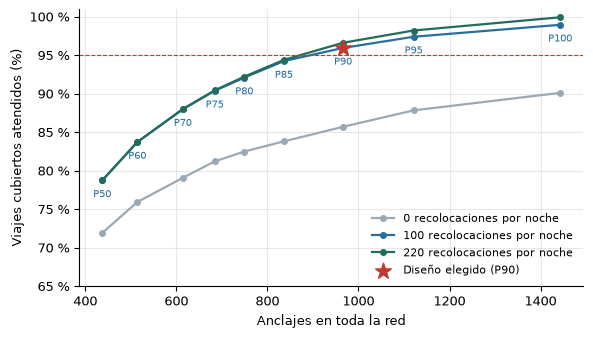

,cuantil,flota,anclajes,pct_atendidos_cubiertos,n_sin_patinete,n_sin_anclaje,viajes_por_patinete_dia,puntos_por_100_anclajes
0,0.50,229,437,78.73,1272,1580,2.19,NaN
1,0.60,262,514,83.71,1013,1171,2.04,6.47
2,0.70,302,614,87.98,807,805,1.86,4.27
3,0.75,343,684,90.37,585,706,1.68,3.42
4,0.80,375,749,92.09,471,590,1.57,2.64
5,0.85,412,836,94.24,339,434,1.46,2.47
6,0.90,474,966,95.94,240,304,1.29,1.31
7,0.95,549,1121,97.40,147,202,1.13,0.94
8,1.00,699,1443,98.95,51,90,0.90,0.48


In [3]:
filas = []
for q in CUANTILES:
    s, a = dimensionar(ref, q)
    for reb in REBALANCEOS:
        r = simular(dem, red, s, a, reb).resumen
        filas.append({"cuantil": q, "rebalanceo_max": reb, **{k: v for k, v in r.items() if k not in ("rebalanceo_max", "desvio")}})
barrido = pd.DataFrame(filas)
guardar(barrido, "T32_dimensionado")

base = barrido.loc[barrido["rebalanceo_max"].eq(REBALANCEO_BASE)].reset_index(drop=True)
cumple = base.loc[base["pct_atendidos_cubiertos"].ge(SERVICIO_OBJETIVO)]
q_elegido = float(cumple["cuantil"].min()) if len(cumple) else 1.0
elegido = base.loc[base["cuantil"].eq(q_elegido)].iloc[0]
base["anclajes_extra"] = base["anclajes"].diff()
base["puntos_extra"] = base["pct_atendidos_cubiertos"].diff()
base["puntos_por_100_anclajes"] = 100 * base["puntos_extra"] / base["anclajes_extra"]

fig, ax = plt.subplots(figsize=(6.5, 3.6))
colores = {0: "#9aa9b3", 100: "#2a6f9b", 220: "#226c5b"}
for reb, g in barrido.groupby("rebalanceo_max"):
    ax.plot(g["anclajes"], g["pct_atendidos_cubiertos"], marker="o", ms=4, lw=1.6, color=colores.get(reb, "#444"),
            label=f"{reb} recolocaciones por noche")
ax.scatter([elegido["anclajes"]], [elegido["pct_atendidos_cubiertos"]], s=140, marker="*", color="#c0392b", zorder=5,
           label=f"Diseño elegido (P{round(100 * q_elegido)})")
ax.axhline(SERVICIO_OBJETIVO, color="#c0392b", lw=.8, ls="--")
for _, f in base.iterrows():
    ax.annotate(f"P{round(100 * f['cuantil'])}", (f["anclajes"], f["pct_atendidos_cubiertos"]), textcoords="offset points",
                xytext=(0, -12), ha="center", fontsize=7, color="#2a6f9b")
ax.set(xlabel="Anclajes en toda la red", ylabel="Viajes cubiertos atendidos (%)", ylim=(65, 101))
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0f} %")
ax.legend(frameon=False, loc="lower right")
guardar_figura(fig, "movilidad", "T32_dimensionado")
display(base[["cuantil", "flota", "anclajes", "pct_atendidos_cubiertos", "n_sin_patinete", "n_sin_anclaje",
              "viajes_por_patinete_dia", "puntos_por_100_anclajes"]].round(2))

**Conclusiones.**
- Con 100 recolocaciones por noche, **el diseño P90 es el primero que llega al 95 %**: 474 patinetes y 966 anclajes atienden el 95,9 % de los viajes cubiertos. P85 se queda en el 94,2 %.
- Cada anclaje más rinde cada vez menos. De P60 a P70, cada 100 anclajes suman 4,3 puntos; de P90 a P95, 0,9 puntos; de P95 a P100, 0,5 puntos.
- Sin rebalanceo, ni el diseño P100 llega al 95 % (se queda en el 90,1 %). En cambio, pasar de 100 a 220 recolocaciones apenas mejora el P90 (del 95,9 % al 96,6 %): con este tamaño de estaciones, lo que más limita es la capacidad y no el rebalanceo.
- Con los anclajes del P90 fijados, T34 busca la menor flota que sigue en el 95 %: **400 patinetes** (95,1 %). Es la flota que se usa desde aquí. El stock de diseño (474) solo decide cómo se reparten entre estaciones.

## 4. Estaciones de la red elegida

**Qué queremos ver.** Con los anclajes del diseño elegido, la flota de 400 patinetes repartida en proporción al stock de diseño y el rebalanceo base: stock inicial, anclajes, salidas, llegadas, rotación (salidas por anclaje y día), ocupación media y tiempo vacía o llena de cada estación. También los rechazos por causa, los desvíos y lo que pasa si no se permite desviar.

**Por qué importa.** Es el catálogo que pide el enunciado y el que leen T31, T33, T34 y la fase de consumo. Las estaciones que pasan mucho tiempo vacías o llenas son las candidatas a cambiar de tamaño o a recibir más rebalanceo.

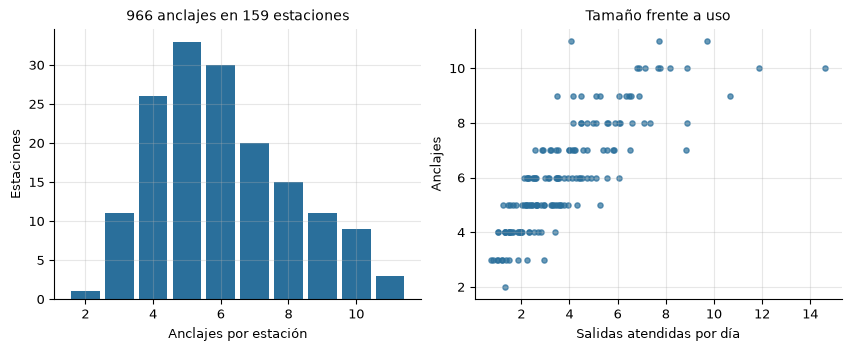

atendido         12750
sin_patinete       472
sin_anclaje        187
sin_cobertura     3347
dtype: int64

,lon,lat,stock_inicial,stock_diseno,anclajes,salidas,llegadas,rotacion_dia,ocupacion_media_pct,pct_tiempo_vacia,pct_tiempo_llena
mean,12.49,41.89,2.52,2.98,6.08,80.19,80.19,0.60,41.45,7.72,3.08
50%,12.48,41.89,2.00,3.00,6.00,71.00,70.00,0.58,41.49,6.63,1.99
max,12.53,41.94,6.00,7.00,11.00,307.00,259.00,1.46,58.67,23.76,14.96


Sin desvío: 92.96 % atendidos; con desvío: 95.09 %
Noches con el límite agotado: 16 de 20


In [4]:
stock_diseno, anclajes = dimensionar(ref, q_elegido)
stock = repartir_flota(stock_diseno, anclajes, FLOTA)
sim = simular(dem, red, stock, anclajes, REBALANCEO_BASE)
sin_desvio = simular(dem, red, stock, anclajes, REBALANCEO_BASE, desvio=False).resumen
catalogo = sim.estaciones.assign(network_id=red_id, stock_diseno=stock_diseno)[
    ["network_id", "station_id", "lon", "lat", "stock_inicial", "stock_diseno", "anclajes", "salidas", "llegadas", "rotacion_dia",
     "ocupacion_media_pct", "pct_tiempo_vacia", "pct_tiempo_llena"]]
guardar(catalogo, "T32_estaciones")
noches = sim.noches.assign(fecha=pd.to_datetime(sim.noches["corte"], unit="s").dt.strftime("%Y-%m-%d")).drop(columns="corte")
guardar(noches, "T32_noches")
carpeta = TABLAS.parents[2] / "datos" / "procesados"
sim.viajes.to_parquet(carpeta / "T32_viajes_simulados.parquet", index=False)

resumen = pd.Series({**sim.resumen, "cuantil": q_elegido, "flota_diseno": int(stock_diseno.sum()), "pct_atendidos_sin_desvio": sin_desvio["pct_atendidos_cubiertos"],
                     "estaciones": red.n, "radio_m": radio})
guardar(resumen.rename_axis("indicador").reset_index(name="valor"), "T32_resumen")

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.4), layout="constrained")
axes[0].hist(catalogo["anclajes"], bins=np.arange(1.5, catalogo["anclajes"].max() + 1.5), color="#2a6f9b", rwidth=.85)
axes[0].set(xlabel="Anclajes por estación", ylabel="Estaciones", title=f"{int(catalogo['anclajes'].sum())} anclajes en {red.n} estaciones")
axes[1].scatter(catalogo["salidas"] / sim.resumen["dias"], catalogo["anclajes"], s=14, color="#2a6f9b", alpha=.7)
axes[1].set(xlabel="Salidas atendidas por día", ylabel="Anclajes", title="Tamaño frente a uso")
guardar_figura(fig, "movilidad", "T32_estaciones")

causas = pd.Series({c: sim.resumen[f"n_{c}"] for c in ("atendido", "sin_patinete", "sin_anclaje", "sin_cobertura")})
display(causas, catalogo.describe().loc[["mean", "50%", "max"]].round(2))
print(f"Sin desvío: {sin_desvio['pct_atendidos_cubiertos']:.2f} % atendidos; con desvío: {sim.resumen['pct_atendidos_cubiertos']:.2f} %")
print(f"Noches con el límite agotado: {(noches['patinetes_movidos'] == REBALANCEO_BASE).sum()} de {len(noches)}")

**Conclusiones.**
- **Viajes.** De los 13 409 viajes cubiertos se atienden 12 750 (95,1 %). Se rechazan 472 por falta de patinete y 187 por falta de anclaje. Con 74 patinetes menos que el diseño faltan más patinetes, pero las estaciones se llenan menos.
- **Desvíos.** 298 viajes atendidos se desvían a otra estación, con 85 m de más de media. Sin desvío se atendería el 93,0 %.
- **Tamaño.** Las estaciones tienen de 2 a 11 anclajes (mediana 6) y empiezan el día con 1 a 6 patinetes (mediana 2). Cada una recibe el 84 % de su stock de diseño, redondeado (400 de 474). El tamaño sigue al uso: Spearman de 0,86 entre salidas y anclajes.
- **Ocupación.** La ocupación media es del 41 %. La estación mediana pasa el 6,6 % del tiempo vacía y el 2,0 % llena. Doce estaciones pasan más del 15 % del tiempo vacías y ninguna más del 15 % llena: con esta flota, lo que falta antes es el patinete. Son las primeras a revisar.
- **Rebalanceo.** Se agotan los 100 movimientos en 16 de las 20 noches. Se recorren unos 121 km por noche y quedan de media 10 patinetes por reponer. T33 compara otras políticas.
- **Flota.** Los 400 patinetes hacen 1,52 viajes por patinete y día y están en viaje el 1,2 % del tiempo. Helbiz usó de media 487,8 patinetes distintos al día (T12), pero para todos sus viajes, incluidos los que esta red no cubre.

## 5. El mismo diseño en la semana reservada

**Qué queremos ver.** Las mismas estaciones, anclajes y flota de 400 patinetes, simulados con los viajes del 22 al 28 de febrero.

**Por qué importa.** El dimensionado se ha ajustado con las tres primeras semanas. La reservada tiene un 18 % más de demanda diaria (T12) y dice si el diseño aguanta fuera de la muestra.

In [5]:
dem_res = Demanda.de_viajes(cargar_viajes(periodo="reservada"), red)
reservada = pd.DataFrame([
    {"periodo": periodo, "rebalanceo_max": reb, **{k: v for k, v in simular(d, red, stock, anclajes, reb).resumen.items()
                                                    if k not in ("rebalanceo_max", "desvio")}}
    for periodo, d in (("ajuste", dem), ("reservada", dem_res)) for reb in REBALANCEOS])
guardar(reservada, "T32_reservada")

exportar("fase1", "t32_inventario", {
    "network_id": red_id, "radio_m": radio, "hora_corte": HORA_CORTE, "servicio_objetivo": SERVICIO_OBJETIVO,
    "rebalanceo_base": REBALANCEO_BASE, "cuantil": q_elegido, "flota_diseno": int(stock_diseno.sum()), "cotas": cotas,
    "dimensionado": barrido, "resumen": resumen.to_dict(), "estaciones": catalogo, "noches": noches,
    "reservada": reservada,
})
display(reservada[["periodo", "rebalanceo_max", "solicitudes", "cubiertas", "pct_atendidos_cubiertos",
                   "n_sin_patinete", "n_sin_anclaje", "viajes_por_patinete_dia"]].round(2))

,periodo,rebalanceo_max,solicitudes,cubiertas,pct_atendidos_cubiertos,n_sin_patinete,n_sin_anclaje,viajes_por_patinete_dia
0,ajuste,0,16756,13409,84.86,1414,616,1.35
1,ajuste,100,16756,13409,95.09,472,187,1.52
2,ajuste,220,16756,13409,95.38,456,163,1.52
3,reservada,0,6614,5001,86.02,517,182,1.54
4,reservada,100,6614,5001,93.38,259,72,1.67
5,reservada,220,6614,5001,93.60,253,67,1.67


**Conclusiones.**
- En la semana reservada, con la misma red y 100 recolocaciones por noche, se atiende el 93,4 % de los viajes cubiertos. Es 1,7 puntos menos que en el ajuste, con un 18 % más de demanda diaria.
- Rechazados por falta de patinete: 259. Por falta de anclaje: 72. Con 220 recolocaciones se llega al 93,6 %.
- El diseño aguanta fuera de la muestra, aunque queda debajo del objetivo del 95 %. Con los 474 patinetes del diseño se llegaría al 94,2 % (T34).

## Decisiones

| Decisión | Valor propuesto | Evidencia | Periodo | Limitaciones | Qué cambia en el plan |
|---|---|---|---|---|---|
| Regla de dimensionado | Stock de diseño = P90 diario del stock necesario de cada estación; anclajes = ese stock + P90 de lo que sube el inventario en un día (mínimo 1 y 2) | `T32_dimensionado.csv`, figura `T32_dimensionado` | Ajuste | Se ajusta con el rebalanceo perfecto y se comprueba con rebalanceo limitado | El catálogo `T32_estaciones.csv` es la red que leen T31, T33, T34 y consumo |
| Nivel de servicio | 95 % de los viajes cubiertos con 100 recolocaciones por noche: el P90 da 966 anclajes y 474 patinetes de diseño (95,9 %) | `T32_resumen.csv`, `T32_dimensionado.csv` | Ajuste | El 20 % sin estación en algún extremo no entra en el inventario | T34 barre la flota con estos anclajes |
| Flota | 400 patinetes repartidos en proporción al stock de diseño (95,1 %), la menor que llega al 95 % según T34 | `T32_resumen.csv`, `T34_curva_flota.csv` | Ajuste | Si cambian los anclajes, T34 avisa de que hay que cambiar `FLOTA` | El stock inicial del catálogo es el de los 400 |
| Desvío dentro del radio | Sí: recupera 2,1 puntos de servicio con 85 m de más de media | `T32_resumen.csv` | Ajuste | Distancia en línea recta; T29 muestra que a pie es más | — |
| Rebalanceo nocturno | 100 por noche (base); 220 apenas mejora el servicio (95,4 %) | `T32_noches.csv`, `T32_reservada.csv` | Ajuste | Política voraz hacia el stock inicial, a las 4 h | T33 compara políticas y kilómetros |
| Validación | La misma red atiende el 93,4 % en la semana reservada | `T32_reservada.csv` | Reservada | Una sola semana | Margen a tener en cuenta si la demanda crece |